In [1]:
import sys
import numpy as np
import pandas as pd
import openpyxl

print("Python:", sys.executable)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("OpenPyXL:", openpyxl.__version__)

Python: c:\Users\S_Gayathri\skill-gap-analyzer\.venv\Scripts\python.exe
NumPy: 2.5.4
Pandas: 3.0.6
OpenPyXL: 3.1.5


In [3]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Project directory
PROJECT_DIR = Path.cwd().parent

# O*NET Excel file paths
ONET_DIR = PROJECT_DIR / "data" / "onet" / "db_31_0_excel"

OCCUPATION_PATH = ONET_DIR / "Occupation Data.xlsx"
ESSENTIAL_SKILLS_PATH = ONET_DIR / "Essential Skills.xlsx"
SOFTWARE_SKILLS_PATH = ONET_DIR / "Software Skills.xlsx"

# Verify paths
print("Project directory:", PROJECT_DIR)
print("O*NET directory:", ONET_DIR)
print("Occupation file exists:", OCCUPATION_PATH.exists())
print("Essential Skills file exists:", ESSENTIAL_SKILLS_PATH.exists())
print("Software Skills file exists:", SOFTWARE_SKILLS_PATH.exists())

Project directory: c:\Users\S_Gayathri\skill-gap-analyzer
O*NET directory: c:\Users\S_Gayathri\skill-gap-analyzer\data\onet\db_31_0_excel
Occupation file exists: True
Essential Skills file exists: True
Software Skills file exists: True


In [5]:

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_DIR = Path.cwd()

# If the notebook was opened from another directory,
# use the project root explicitly.
if not (PROJECT_DIR / "data").exists():
    PROJECT_DIR = Path(r"C:\Users\S_Gayathri\skill-gap-analyzer")

DATA_DIR = PROJECT_DIR / "data"
REPORT_DIR = PROJECT_DIR / "reports" / "figures"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

RESUME_PATH = DATA_DIR / "resumes" / "Resume" / "Resume.csv"
POSTINGS_PATH = DATA_DIR / "job_postings" / "postings.csv"
JOB_SKILLS_PATH = DATA_DIR / "job_postings" / "jobs" / "job_skills.csv"
SKILL_MAPPING_PATH = DATA_DIR / "job_postings" / "mappings" / "skills.csv"

ONET_DIR = DATA_DIR / "onet" / "db_31_0_excel"
OCCUPATION_PATH = ONET_DIR / "Occupation Data.xlsx"
ESSENTIAL_SKILLS_PATH = ONET_DIR / "Essential Skills.xlsx"
SOFTWARE_SKILLS_PATH = ONET_DIR / "Software Skills.xlsx"

print("Project directory:", PROJECT_DIR)
print("Resume CSV exists:", RESUME_PATH.exists())
print("Job postings CSV exists:", POSTINGS_PATH.exists())
print("Job skills CSV exists:", JOB_SKILLS_PATH.exists())
print("O*NET occupation file exists:", OCCUPATION_PATH.exists())
print("Figure output directory:", REPORT_DIR)


Project directory: C:\Users\S_Gayathri\skill-gap-analyzer
Resume CSV exists: True
Job postings CSV exists: True
Job skills CSV exists: True
O*NET occupation file exists: True
Figure output directory: C:\Users\S_Gayathri\skill-gap-analyzer\reports\figures


In [4]:
occupations = pd.read_excel(OCCUPATION_PATH)
essential_skills = pd.read_excel(ESSENTIAL_SKILLS_PATH)
software_skills = pd.read_excel(SOFTWARE_SKILLS_PATH)

print("Occupations shape:", occupations.shape)
print("Essential skills shape:", essential_skills.shape)
print("Software skills shape:", software_skills.shape)

display(occupations.head())
display(essential_skills.head())
display(software_skills.head())

Occupations shape: (1016, 3)
Essential skills shape: (18200, 15)
Software skills shape: (31821, 7)


,O*NET-SOC Code,Title,Description
0,11-1011.00,Chief Executives,Determine and formulate policies and provide o...
1,11-1011.03,Chief Sustainability Officers,"Communicate and coordinate with management, sh..."
2,11-1021.00,General and Operations Managers,"Plan, direct, or coordinate the operations of ..."
3,11-1031.00,Legislators,"Develop, introduce, or enact laws and statutes..."
4,11-2011.00,Advertising and Promotions Managers,"Plan, direct, or coordinate advertising polici..."


,O*NET-SOC Code,Title,Element ID,Element Name,Scale ID,Scale Name,Data Value,N,Standard Error,Lower CI Bound,Upper CI Bound,Recommend Suppress,Not Relevant,Date,Domain Source
0,11-1011.00,Chief Executives,2.A.1.a,Reading Comprehension,IM,Importance,4.12,8,0.1250,3.8800,4.3700,N,NaN,08/2023,Analyst
1,11-1011.00,Chief Executives,2.A.1.a,Reading Comprehension,LV,Level,4.62,8,0.1830,4.2664,4.9836,N,N,08/2023,Analyst
2,11-1011.00,Chief Executives,2.A.1.b,Active Listening,IM,Importance,4.00,8,0.0000,4.0000,4.0000,N,NaN,08/2023,Analyst
3,11-1011.00,Chief Executives,2.A.1.b,Active Listening,LV,Level,4.75,8,0.1637,4.4292,5.0708,N,N,08/2023,Analyst
4,11-1011.00,Chief Executives,2.A.1.c,Writing,IM,Importance,4.12,8,0.1250,3.8800,4.3700,N,NaN,08/2023,Analyst


,O*NET-SOC Code,Title,Workplace Example,Element ID,Element Name,Hot Technology,In Demand
0,11-1011.00,Chief Executives,Adobe Acrobat,2.E.5.b,Document management software,Y,N
1,11-1011.00,Chief Executives,AdSense Tracker,2.E.6.f,Data base user interface and query software,N,N
2,11-1011.00,Chief Executives,Atlassian JIRA,2.E.5.a,Content workflow software,Y,N
3,11-1011.00,Chief Executives,Blackbaud The Raiser's Edge,2.E.6.c,Customer relationship management CRM software,N,N
4,11-1011.00,Chief Executives,ComputerEase construction accounting software,2.E.2.a,Accounting software,N,N


In [2]:

resumes = pd.read_csv(RESUME_PATH, low_memory=False)

print("Resume dataset shape:", resumes.shape)
print("\nColumns:")
print(resumes.columns.tolist())

display(resumes.head(5))

print("\nMissing values:")
display(resumes.isnull().sum().to_frame("Missing values"))

print("\nResume categories:")
display(resumes["Category"].value_counts().head(20))


Resume dataset shape: (2484, 4)

Columns:
['ID', 'Resume_str', 'Resume_html', 'Category']


,ID,Resume_str,Resume_html,Category
0,16852973,HR ADMINISTRATOR/MARKETING ASSOCIATE\...,"<div class=""fontsize fontface vmargins hmargin...",HR
1,22323967,"HR SPECIALIST, US HR OPERATIONS ...","<div class=""fontsize fontface vmargins hmargin...",HR
2,33176873,HR DIRECTOR Summary Over 2...,"<div class=""fontsize fontface vmargins hmargin...",HR
3,27018550,HR SPECIALIST Summary Dedica...,"<div class=""fontsize fontface vmargins hmargin...",HR
4,17812897,HR MANAGER Skill Highlights ...,"<div class=""fontsize fontface vmargins hmargin...",HR



Missing values:


,Missing values
ID,0
Resume_str,0
Resume_html,0
Category,0



Resume categories:


Category
INFORMATION-TECHNOLOGY    120
BUSINESS-DEVELOPMENT      120
ADVOCATE                  118
CHEF                      118
FINANCE                   118
ENGINEERING               118
ACCOUNTANT                118
FITNESS                   117
AVIATION                  117
SALES                     116
HEALTHCARE                115
CONSULTANT                115
BANKING                   115
CONSTRUCTION              112
PUBLIC-RELATIONS          111
HR                        110
DESIGNER                  107
ARTS                      103
TEACHER                   102
APPAREL                    97
Name: count, dtype: int64

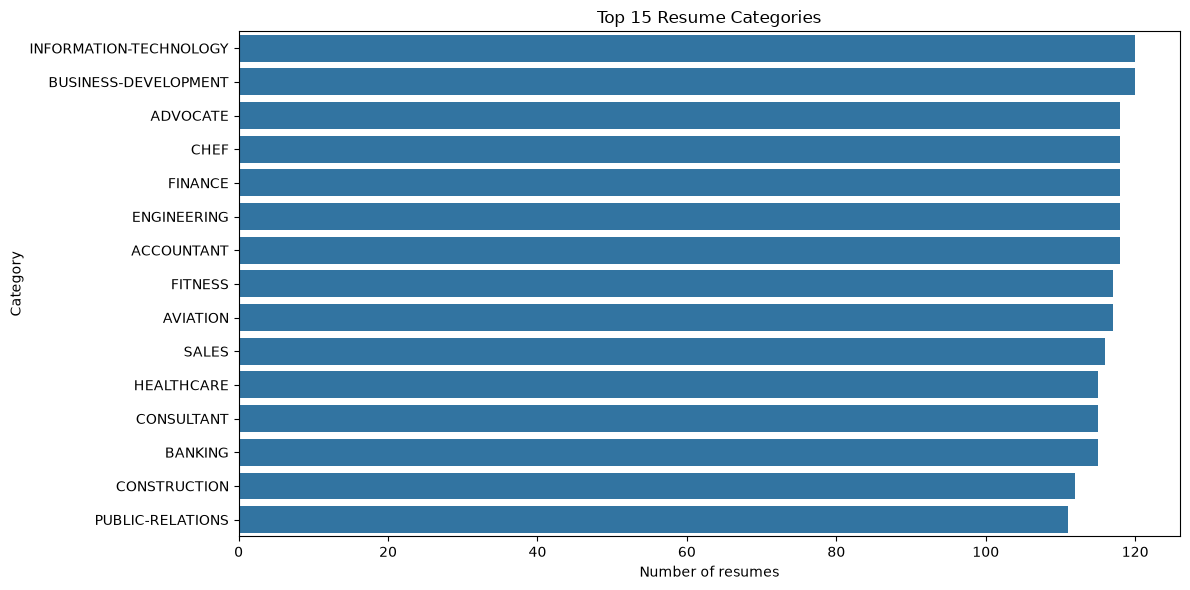

In [3]:

category_counts = resumes["Category"].value_counts().head(15)

plt.figure(figsize=(12, 6))
sns.barplot(x=category_counts.values, y=category_counts.index)
plt.title("Top 15 Resume Categories")
plt.xlabel("Number of resumes")
plt.ylabel("Category")
plt.tight_layout()

plt.savefig(
    REPORT_DIR / "resume_categories.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()


In [4]:

jobs = pd.read_csv(
    POSTINGS_PATH,
    nrows=20_000,
    low_memory=False
)

print("Job-postings sample shape:", jobs.shape)
print("\nColumns:")
print(jobs.columns.tolist())

display(jobs[[
    "job_id",
    "title",
    "description",
    "skills_desc",
    "formatted_experience_level"
]].head(5))

print("\nMissing values in the sample:")
missing_jobs = (
    jobs.isnull()
    .sum()
    .sort_values(ascending=False)
    .to_frame("Missing values")
)

display(missing_jobs.head(15))


Job-postings sample shape: (20000, 31)

Columns:
['job_id', 'company_name', 'title', 'description', 'max_salary', 'pay_period', 'location', 'company_id', 'views', 'med_salary', 'min_salary', 'formatted_work_type', 'applies', 'original_listed_time', 'remote_allowed', 'job_posting_url', 'application_url', 'application_type', 'expiry', 'closed_time', 'formatted_experience_level', 'skills_desc', 'listed_time', 'posting_domain', 'sponsored', 'work_type', 'currency', 'compensation_type', 'normalized_salary', 'zip_code', 'fips']


,job_id,title,description,skills_desc,formatted_experience_level
0,921716,Marketing Coordinator,Job descriptionA leading real estate firm in N...,Requirements: \n\nWe are seeking a College or ...,NaN
1,1829192,Mental Health Therapist/Counselor,"At Aspen Therapy and Wellness , we are committ...",NaN,NaN
2,10998357,Assitant Restaurant Manager,The National Exemplar is accepting application...,We are currently accepting resumes for FOH - A...,NaN
3,23221523,Senior Elder Law / Trusts and Estates Associat...,Senior Associate Attorney - Elder Law / Trusts...,This position requires a baseline understandin...,NaN
4,35982263,Service Technician,Looking for HVAC service tech with experience ...,NaN,NaN



Missing values in the sample:


,Missing values
closed_time,19898
skills_desc,19791
med_salary,18911
remote_allowed,17570
applies,15722
min_salary,15477
max_salary,15477
currency,14388
compensation_type,14388
pay_period,14388


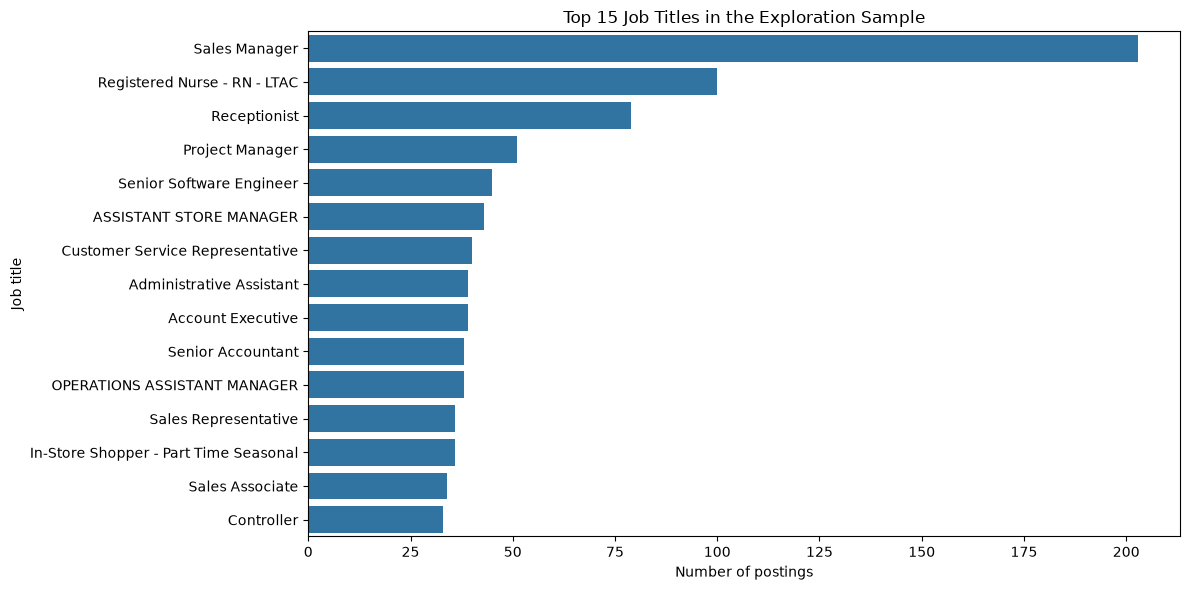

In [5]:

job_title_counts = (
    jobs["title"]
    .dropna()
    .str.strip()
    .replace("", np.nan)
    .dropna()
    .value_counts()
    .head(15)
)

plt.figure(figsize=(12, 6))
sns.barplot(
    x=job_title_counts.values,
    y=job_title_counts.index
)
plt.title("Top 15 Job Titles in the Exploration Sample")
plt.xlabel("Number of postings")
plt.ylabel("Job title")
plt.tight_layout()

plt.savefig(
    REPORT_DIR / "job_title_distribution.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()


In [6]:

job_skills = pd.read_csv(JOB_SKILLS_PATH, nrows=10_000)
skill_mapping = pd.read_csv(SKILL_MAPPING_PATH)

print("Job skills shape (sample):", job_skills.shape)
print("Job skills columns:", job_skills.columns.tolist())

print("\nSkill mapping shape:", skill_mapping.shape)
print("Skill mapping columns:", skill_mapping.columns.tolist())

display(job_skills.head())
display(skill_mapping.head())


Job skills shape (sample): (10000, 2)
Job skills columns: ['job_id', 'skill_abr']

Skill mapping shape: (35, 2)
Skill mapping columns: ['skill_abr', 'skill_name']


,job_id,skill_abr
0,3884428798,MRKT
1,3884428798,PR
2,3884428798,WRT
3,3887473071,SALE
4,3887465684,FIN


,skill_abr,skill_name
0,ART,Art/Creative
1,DSGN,Design
2,ADVR,Advertising
3,PRDM,Product Management
4,DIST,Distribution


In [6]:

occupations = pd.read_excel(OCCUPATION_PATH)
essential_skills = pd.read_excel(ESSENTIAL_SKILLS_PATH)
software_skills = pd.read_excel(SOFTWARE_SKILLS_PATH)

print("Occupations shape:", occupations.shape)
print("Essential skills shape:", essential_skills.shape)
print("Software skills shape:", software_skills.shape)

print("\nOccupation sample:")
display(occupations.head())

print("\nEssential skills sample:")
display(essential_skills.head())

print("\nSoftware skills sample:")
display(software_skills.head())


Occupations shape: (1016, 3)
Essential skills shape: (18200, 15)
Software skills shape: (31821, 7)

Occupation sample:


,O*NET-SOC Code,Title,Description
0,11-1011.00,Chief Executives,Determine and formulate policies and provide o...
1,11-1011.03,Chief Sustainability Officers,"Communicate and coordinate with management, sh..."
2,11-1021.00,General and Operations Managers,"Plan, direct, or coordinate the operations of ..."
3,11-1031.00,Legislators,"Develop, introduce, or enact laws and statutes..."
4,11-2011.00,Advertising and Promotions Managers,"Plan, direct, or coordinate advertising polici..."



Essential skills sample:


,O*NET-SOC Code,Title,Element ID,Element Name,Scale ID,Scale Name,Data Value,N,Standard Error,Lower CI Bound,Upper CI Bound,Recommend Suppress,Not Relevant,Date,Domain Source
0,11-1011.00,Chief Executives,2.A.1.a,Reading Comprehension,IM,Importance,4.12,8,0.1250,3.8800,4.3700,N,NaN,08/2023,Analyst
1,11-1011.00,Chief Executives,2.A.1.a,Reading Comprehension,LV,Level,4.62,8,0.1830,4.2664,4.9836,N,N,08/2023,Analyst
2,11-1011.00,Chief Executives,2.A.1.b,Active Listening,IM,Importance,4.00,8,0.0000,4.0000,4.0000,N,NaN,08/2023,Analyst
3,11-1011.00,Chief Executives,2.A.1.b,Active Listening,LV,Level,4.75,8,0.1637,4.4292,5.0708,N,N,08/2023,Analyst
4,11-1011.00,Chief Executives,2.A.1.c,Writing,IM,Importance,4.12,8,0.1250,3.8800,4.3700,N,NaN,08/2023,Analyst



Software skills sample:


,O*NET-SOC Code,Title,Workplace Example,Element ID,Element Name,Hot Technology,In Demand
0,11-1011.00,Chief Executives,Adobe Acrobat,2.E.5.b,Document management software,Y,N
1,11-1011.00,Chief Executives,AdSense Tracker,2.E.6.f,Data base user interface and query software,N,N
2,11-1011.00,Chief Executives,Atlassian JIRA,2.E.5.a,Content workflow software,Y,N
3,11-1011.00,Chief Executives,Blackbaud The Raiser's Edge,2.E.6.c,Customer relationship management CRM software,N,N
4,11-1011.00,Chief Executives,ComputerEase construction accounting software,2.E.2.a,Accounting software,N,N


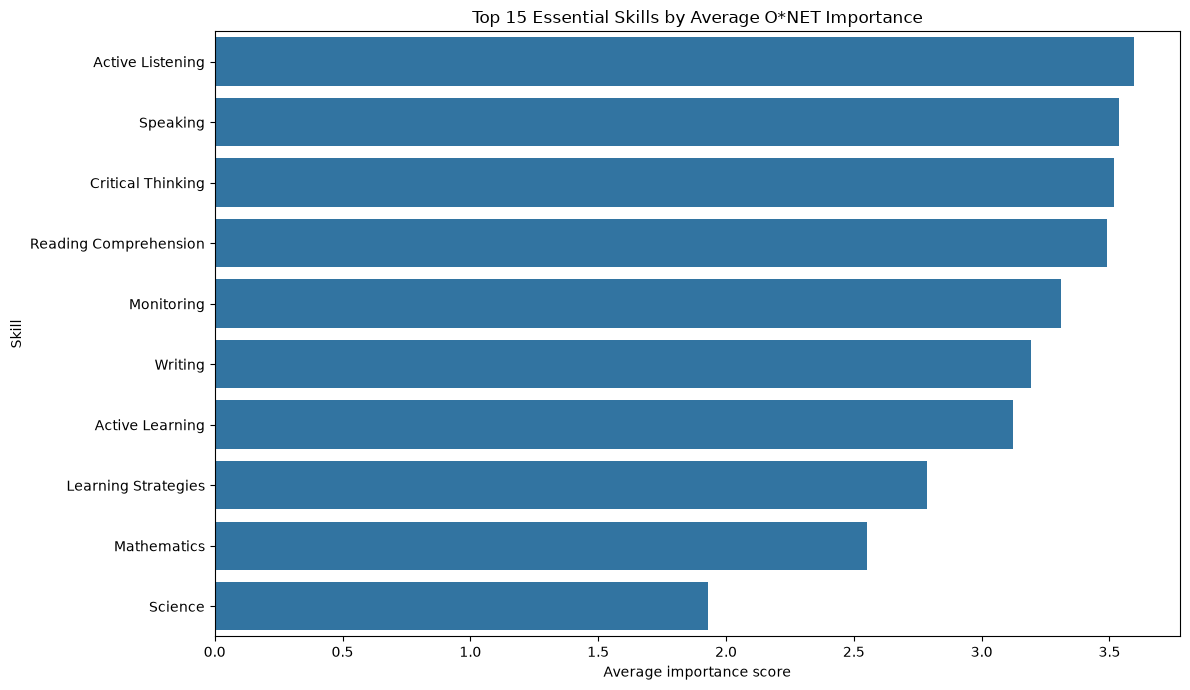

In [7]:

important_skills = essential_skills[
    essential_skills["Scale ID"].eq("IM")
].copy()

# Average importance across occupations for each skill.
top_skills = (
    important_skills.groupby("Element Name")["Data Value"]
    .mean()
    .sort_values(ascending=False)
    .head(15)
)

plt.figure(figsize=(12, 7))
sns.barplot(x=top_skills.values, y=top_skills.index)
plt.title("Top 15 Essential Skills by Average O*NET Importance")
plt.xlabel("Average importance score")
plt.ylabel("Skill")
plt.tight_layout()

plt.savefig(
    REPORT_DIR / "onet_essential_skills.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()


In [9]:
REPORT_DIR.mkdir(parents=True, exist_ok=True)
(PROJECT_DIR / "reports").mkdir(parents=True, exist_ok=True)

In [11]:

from pathlib import Path
import pandas as pd

PROJECT_DIR = Path(r"C:\Users\S_Gayathri\skill-gap-analyzer")
DATA_DIR = PROJECT_DIR / "data"

# Load the datasets
resumes = pd.read_csv(
    DATA_DIR / "resumes" / "Resume" / "Resume.csv",
    low_memory=False
)

# Load only a sample of the large job-postings file
jobs = pd.read_csv(
    DATA_DIR / "job_postings" / "postings.csv",
    nrows=20_000,
    low_memory=False
)

job_skills = pd.read_csv(
    DATA_DIR / "job_postings" / "jobs" / "job_skills.csv",
    nrows=10_000
)

ONET_DIR = DATA_DIR / "onet" / "db_31_0_excel"

occupations = pd.read_excel(
    ONET_DIR / "Occupation Data.xlsx"
)

essential_skills = pd.read_excel(
    ONET_DIR / "Essential Skills.xlsx"
)

software_skills = pd.read_excel(
    ONET_DIR / "Software Skills.xlsx"
)

print("All datasets loaded successfully!")
print("Resumes:", resumes.shape)
print("Job postings sample:", jobs.shape)
print("Job skills sample:", job_skills.shape)
print("O*NET occupations:", occupations.shape)
print("O*NET essential skills:", essential_skills.shape)
print("O*NET software skills:", software_skills.shape)


All datasets loaded successfully!
Resumes: (2484, 4)
Job postings sample: (20000, 31)
Job skills sample: (10000, 2)
O*NET occupations: (1016, 3)
O*NET essential skills: (18200, 15)
O*NET software skills: (31821, 7)


In [12]:

summary = pd.DataFrame({
    "Dataset": [
        "Resume dataset",
        "Job postings exploration sample",
        "Job skills exploration sample",
        "O*NET occupations",
        "O*NET essential skills",
        "O*NET software skills",
    ],
    "Rows loaded": [
        len(resumes),
        len(jobs),
        len(job_skills),
        len(occupations),
        len(essential_skills),
        len(software_skills),
    ],
})

display(summary)

summary.to_csv(
    PROJECT_DIR / "reports" / "data_exploration_summary.csv",
    index=False
)

print("Exploration summary saved.")
print("Charts saved in:", REPORT_DIR)


,Dataset,Rows loaded
0,Resume dataset,2484
1,Job postings exploration sample,20000
2,Job skills exploration sample,10000
3,O*NET occupations,1016
4,O*NET essential skills,18200
5,O*NET software skills,31821


Exploration summary saved.
Charts saved in: C:\Users\S_Gayathri\skill-gap-analyzer\reports\figures
